In [3]:
# All imports and Setup
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
os.makedirs("images", exist_ok=True)

def save_show(name):
    plt.tight_layout()
    plt.savefig(f"images/{name}.png", dpi = 150, bbox_inches= "tight")
    plt.show()

In [4]:
# Load and view 1st 5 rows
df = pd.read_excel("Cleaned_Dataset.xlsx")
df.head()

,OrderID,Date,CustomerID,Product,Quantity,UnitPrice,ShippingAddress,PaymentMethod,OrderStatus,TrackingNumber,ItemsInCart,CouponCode,ReferralSource,TotalPrice
0,ORD200000,2023-01-04,C72649,Monitor,5,570.62,928 Main St,Debit Card,Shipped,TRK37947903,7,SAVE10,Instagram,2853.10
1,ORD200001,2024-08-23,C75739,Phone,2,151.35,823 Main St,Online,Shipped,TRK91186779,3,SAVE10,Referral,302.70
2,ORD200002,2024-02-27,C81728,Tablet,5,550.68,512 Main St,Credit Card,Cancelled,TRK42903982,8,FREESHIP,Email,2753.40
3,ORD200003,2023-10-15,C33540,Chair,1,273.19,275 Main St,Debit Card,Returned,TRK62788070,5,SAVE10,Facebook,273.19
4,ORD200004,2025-05-08,C81840,Printer,4,626.01,668 Main St,Online,Delivered,TRK29241424,8,SAVE10,Email,2504.04


In [11]:
# Data Inspection
print("Shape : ",df.shape)
df.info()
print("Missing values:", df.isna().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())

# checking is OrderID Unique
print("OrderID Unique ?:", df["OrderID"].is_unique)

# Checking are prices calculated correctly
print("TotalPrice Correct?:", ((df.Quantity*df.UnitPrice).round(2) == df.TotalPrice.round(2)).all())


Shape :  (1200, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   OrderID          1200 non-null   object 
 1   Date             1200 non-null   object 
 2   CustomerID       1200 non-null   object 
 3   Product          1200 non-null   object 
 4   Quantity         1200 non-null   int64  
 5   UnitPrice        1200 non-null   float64
 6   ShippingAddress  1200 non-null   object 
 7   PaymentMethod    1200 non-null   object 
 8   OrderStatus      1200 non-null   object 
 9   TrackingNumber   1200 non-null   object 
 10  ItemsInCart      1200 non-null   int64  
 11  CouponCode       1200 non-null   object 
 12  ReferralSource   1200 non-null   object 
 13  TotalPrice       1200 non-null   float64
dtypes: float64(2), int64(2), object(10)
memory usage: 131.4+ KB
Missing values: 0
Duplicate Rows: 0
OrderID Unique ?: True
TotalPrice Co

In [35]:
# Feature Engineering
# Making new columns from data for better trend analysis

df["Date"] = pd.to_datetime(df["Date"])
df["Year"] = df.Date.dt.year
df["Month"] = df.Date.dt.month
df["Quarter"] = df.Date.dt.to_period("Q").astype(str)
df["YearMonth"] = df.Date.dt.to_period("M").astype(str)
df["DayName"] = df.Date.dt.day_name()

# column groups
num = ["Quantity", "UnitPrice", "ItemsInCart", "TotalPrice"]
cat = ["Product", "PaymentMethod", "OrderStatus", "CouponCode", "ReferralSource"]


In [23]:
# Basic Statistics
df[num].agg(["count", "mean", "median", "std", "max", "min"]).round(2)

,Quantity,UnitPrice,ItemsInCart,TotalPrice
count,1200.00,1200.00,1200.00,1200.00
mean,2.95,356.41,5.48,1053.97
median,3.00,364.21,5.00,823.62
std,1.41,197.18,2.28,819.86
max,5.00,699.93,10.00,3456.40
min,1.00,11.39,1.00,11.39


In [24]:
# Five_number summary (min, Q1, median , Q3, max)
df[num].describe().round(2)

,Quantity,UnitPrice,ItemsInCart,TotalPrice
count,1200.00,1200.00,1200.00,1200.00
mean,2.95,356.41,5.48,1053.97
std,1.41,197.18,2.28,819.86
min,1.00,11.39,1.00,11.39
25%,2.00,186.06,4.00,410.52
50%,3.00,364.21,5.00,823.62
75%,4.00,521.57,7.00,1578.48
max,5.00,699.93,10.00,3456.40


In [31]:
# Skewness 
df[num].skew().round(2)

Quantity       0.03
UnitPrice     -0.03
ItemsInCart    0.00
TotalPrice     0.89
dtype: float64

In [36]:
# Categorical Columns: count and percentage
for c in cat:
    print(f"--- {c} ---")
    print(pd.DataFrame({"count:": df[c].value_counts(), "percent": (df[c].value_counts(normalize= True)*100).round(1)}), "\n")

--- Product ---
         count:  percent
Product                 
Printer     181     15.1
Tablet      179     14.9
Chair       178     14.8
Laptop      173     14.4
Desk        170     14.2
Monitor     163     13.6
Phone       156     13.0 

--- PaymentMethod ---
               count:  percent
PaymentMethod                 
Online            258     21.5
Cash              246     20.5
Credit Card       234     19.5
Debit Card        232     19.3
Gift Card         230     19.2 

--- OrderStatus ---
             count:  percent
OrderStatus                 
Cancelled       250     20.8
Returned        247     20.6
Pending         237     19.8
Shipped         235     19.6
Delivered       231     19.2 

--- CouponCode ---
               count:  percent
CouponCode                    
FREESHIP          313     26.1
No CouponCode     309     25.8
WINTER15          292     24.3
SAVE10            286     23.8 

--- ReferralSource ---
                count:  percent
ReferralSource               

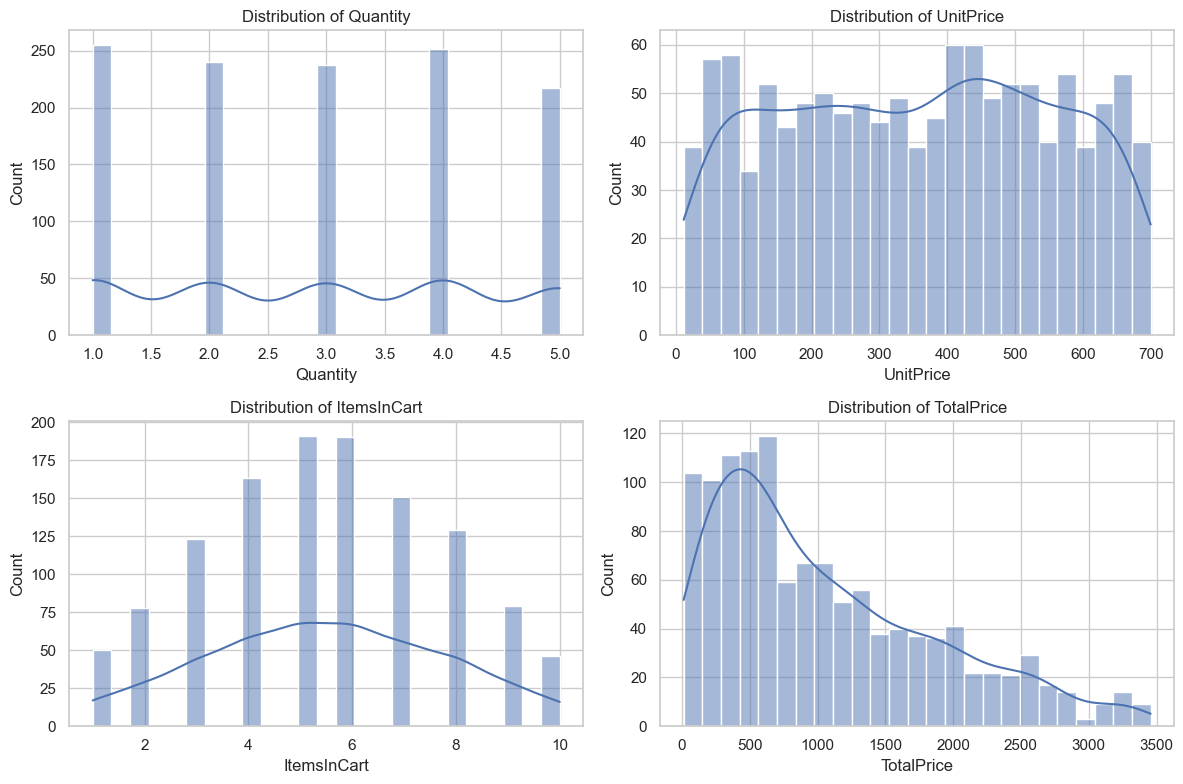

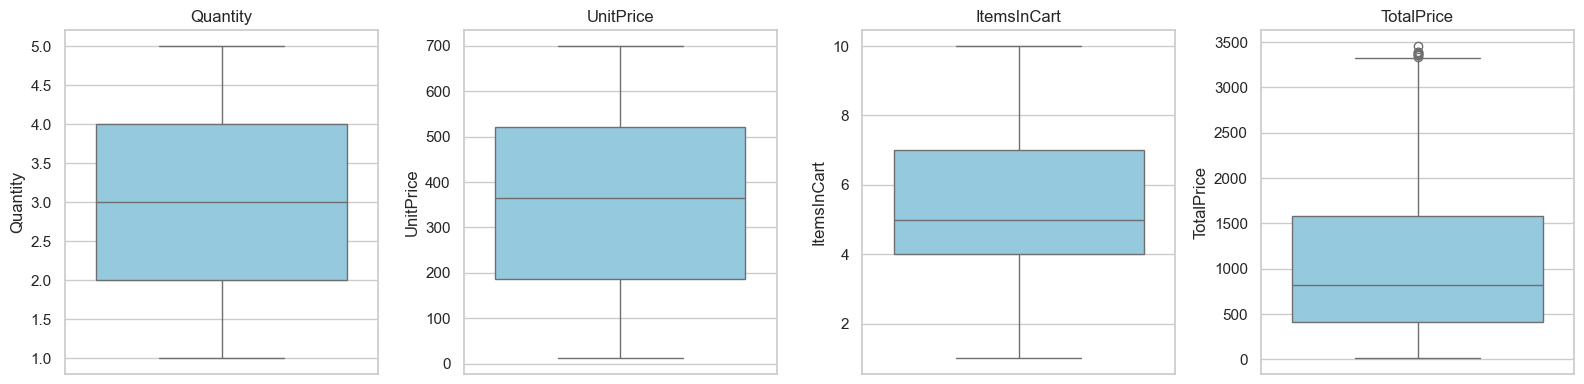

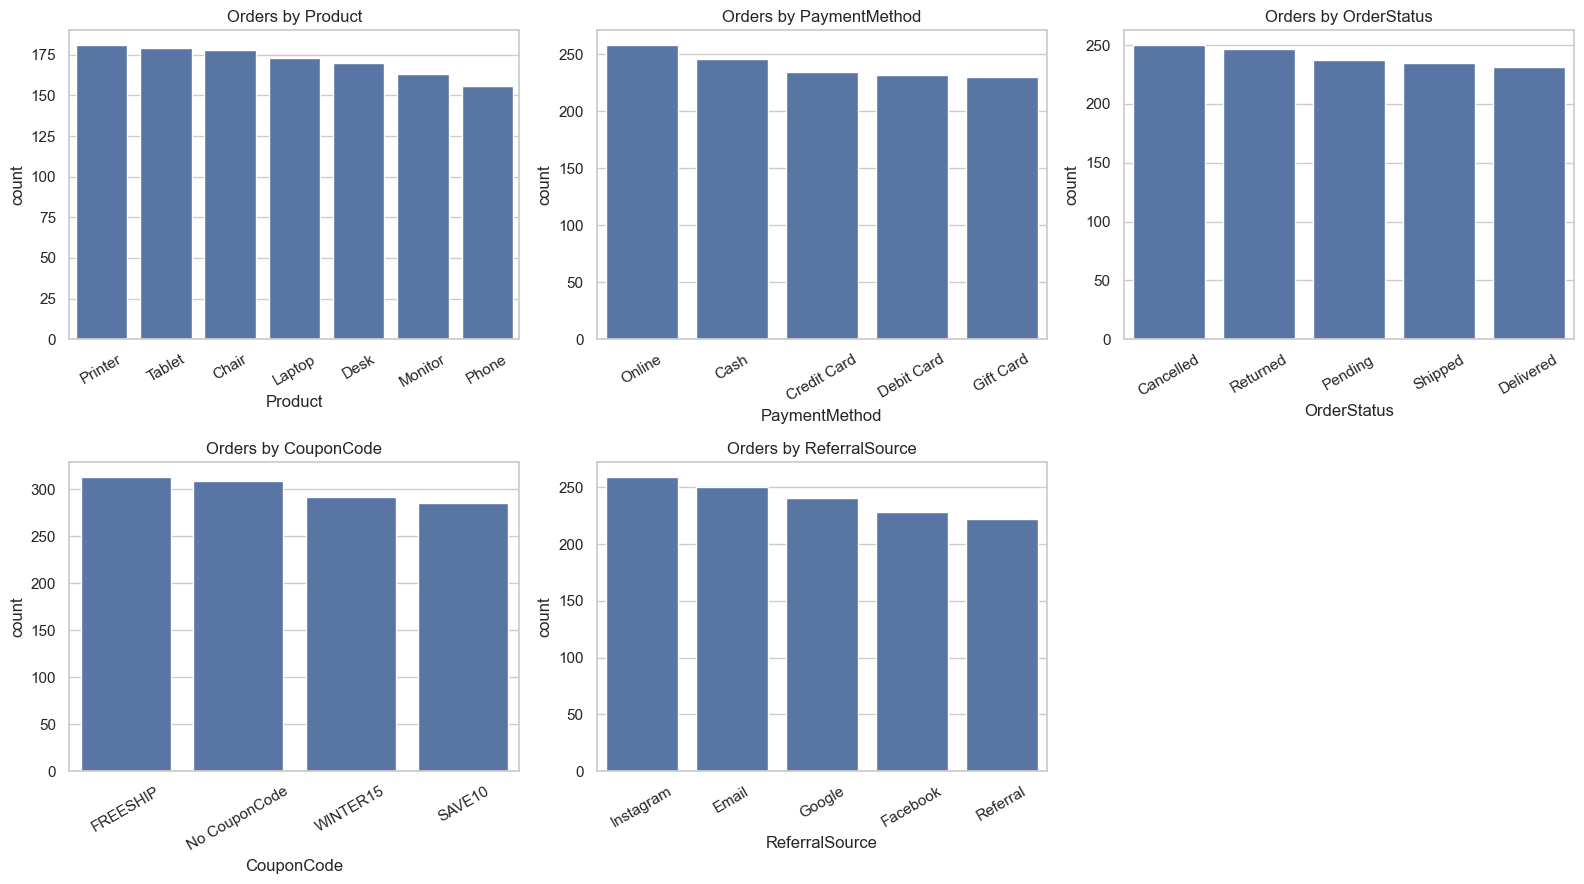

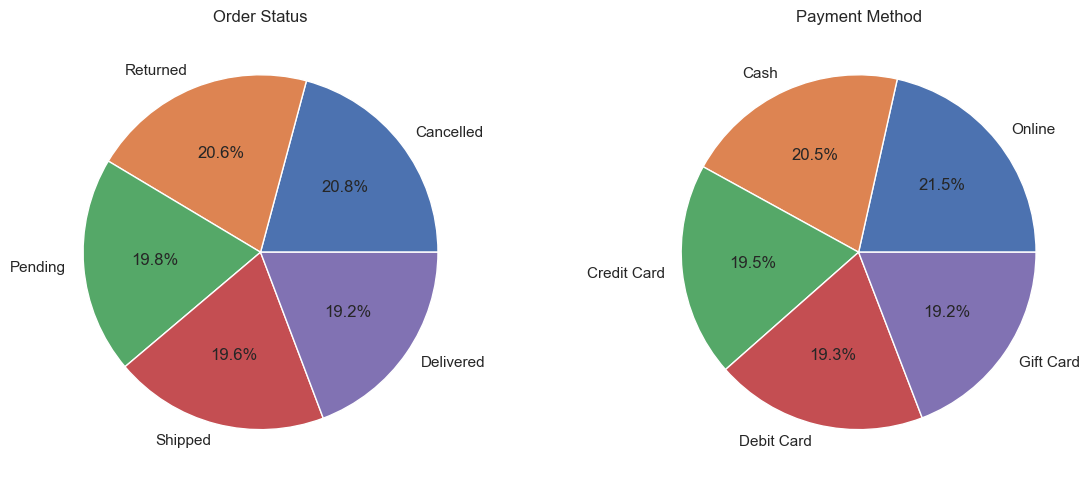

In [42]:
# Distributions 
# Histogram + KDE : Data Shape
fig , ax = plt.subplots(2, 2, figsize= (12,8))

for a, c in zip(ax.ravel(), num):
    sns.histplot(df[c], kde= True, bins = 25, ax= a)
    a.set_title(f"Distribution of {c}")
    plt.tight_layout()
save_show("1: Histograms")

# Boxplots: detecting outliers
fig , ax = plt.subplots(1, 4, figsize= (16,4))
for a, c in zip(ax, num):
    sns.boxplot(y= df[c], ax=a, color="skyblue")
    a.set_title(c)
save_show("2: Boxplots")

# Categorical counterplots
fig , ax = plt.subplots(2, 3, figsize= (16,9))
for a, c in zip(ax.ravel(), cat):
    sns.countplot(data = df , x=c, order= df[c].value_counts().index, ax = a)
    a.set_title(f"Orders by {c}")
    a.tick_params(axis= "x", rotation = 30)
    plt.tight_layout()
ax[1, 2].axis("off")
save_show("3: countplots")

# pie charts
fig , ax = plt.subplots(1, 2, figsize= (12,5))
df.OrderStatus.value_counts().plot.pie(autopct = "%1.1f%%", ax = ax[0], title= "Order Status")
ax[0].set_ylabel("")
df.PaymentMethod.value_counts().plot.pie(autopct = "%1.1f%%", ax = ax[1], title= "Payment Method")
ax[1].set_ylabel("")
save_show("4: Pies")


In [43]:
# Outliers Detection
# IQR Method 
q1, q3 = df.TotalPrice.quantile([.25, .75])
iqr = q3 - q1
low, high = q1 - 1.5*iqr , q3 + 1.5*iqr
outliers = df[(df.TotalPrice < low) | (df.TotalPrice > high)]
print(f"IQR bounds: {low:.0f} to {high:.0f} | Outliers: {len(outliers)}")
outliers[["OrderID", "Product", "Quantity", "UnitPrice", "TotalPrice"]].sort_values("TotalPrice", ascending=False)

IQR bounds: -1341 to 3330 | Outliers: 8


,OrderID,Product,Quantity,UnitPrice,TotalPrice
789,ORD200789,Tablet,5,691.28,3456.40
1122,ORD201122,Monitor,5,678.19,3390.95
632,ORD200632,Laptop,5,678.16,3390.80
469,ORD200469,Chair,5,676.98,3384.90
328,ORD200328,Tablet,5,674.04,3370.20
107,ORD200107,Printer,5,670.75,3353.75
326,ORD200326,Laptop,5,670.48,3352.40
1065,ORD201065,Printer,5,666.80,3334.00


Z-Score outliers (|z|>3:) 0


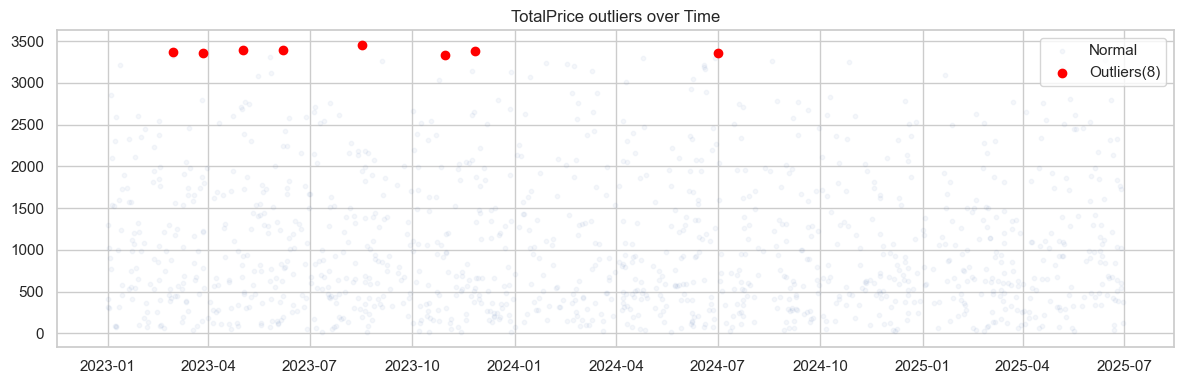

In [55]:
# z-score method
z = (df.TotalPrice - df.TotalPrice.mean()) / df.TotalPrice.std()
print("Z-Score outliers (|z|>3:)", (z.abs() > 3).sum())

plt.figure(figsize= (12, 4))
plt.scatter(df.Date, df.TotalPrice, s=10, alpha=.05, label= "Normal")
plt.scatter(outliers.Date, outliers.TotalPrice, color ="red", label= f"Outliers({len(outliers)})")
plt.legend()
plt.title("TotalPrice outliers over Time")
save_show("5: Outliers")

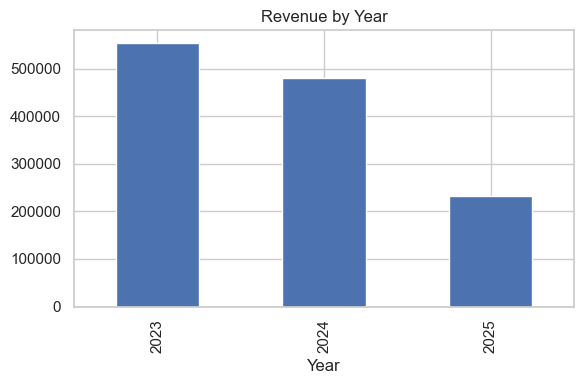

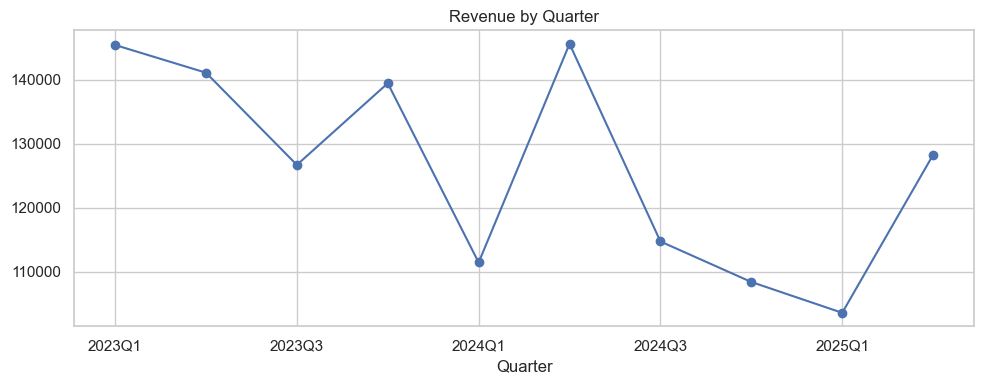

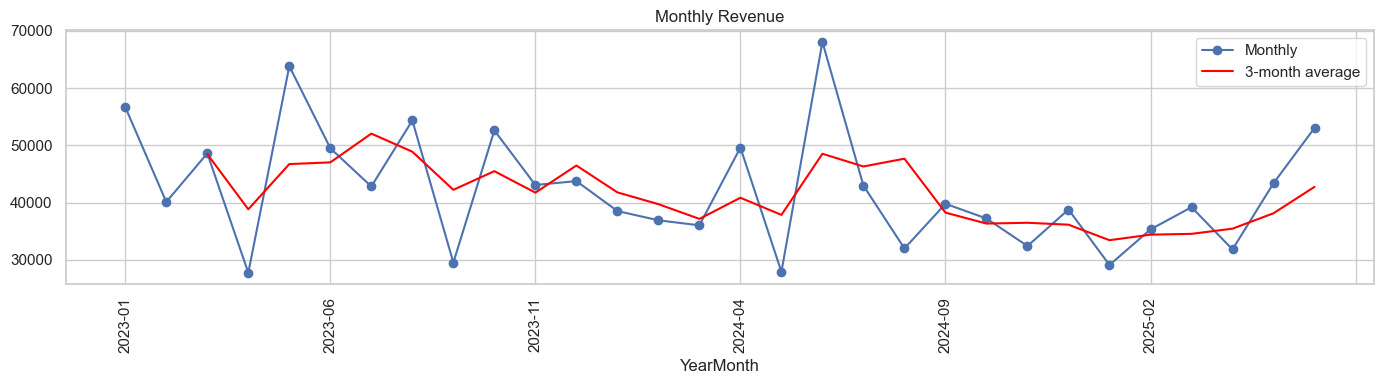

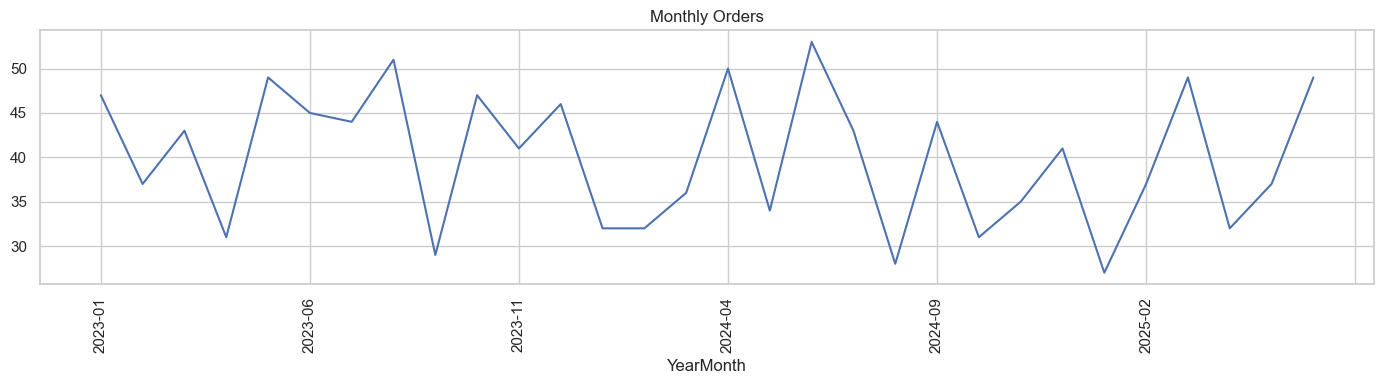

Year
2023    286502.0
2024    257059.0
2025    231883.0
Name: TotalPrice, dtype: float64
Year
2023     NaN
2024   -10.3
2025    -9.8
Name: TotalPrice, dtype: float64


In [66]:
# Trends over Time
# Yearly and Quaterly Revenue

df.groupby("Year").TotalPrice.sum().plot.bar(figsize= (6,4), title= "Revenue by Year")
save_show("6: Yearly")

df.groupby("Quarter").TotalPrice.sum().plot(marker= "o", figsize=(10,4), title="Revenue by Quarter")
save_show("7: Quarterly")

# Monthly revenue + 3-month moving average
m = df.groupby("YearMonth").TotalPrice.sum()
plt.figure(figsize=(14,4))
m.plot(marker="o", label= "Monthly")
m.rolling(3).mean().plot(color = "red", label= "3-month average")
plt.xticks(rotation = 90)
plt.legend()
plt.title("Monthly Revenue")
save_show("8: Monthly")

# Monthly orders count
df.groupby("YearMonth").size().plot(figsize=(14,4), rot=90, title= "Monthly Orders")
save_show("9: Monthly orders")

# Fair Comparison: only jan-jun (because 2025 has only six months)
h1 = df[df.Month <= 6].groupby("Year").TotalPrice.sum()
print(h1.round(0))
print(h1.pct_change().mul(100).round(1))


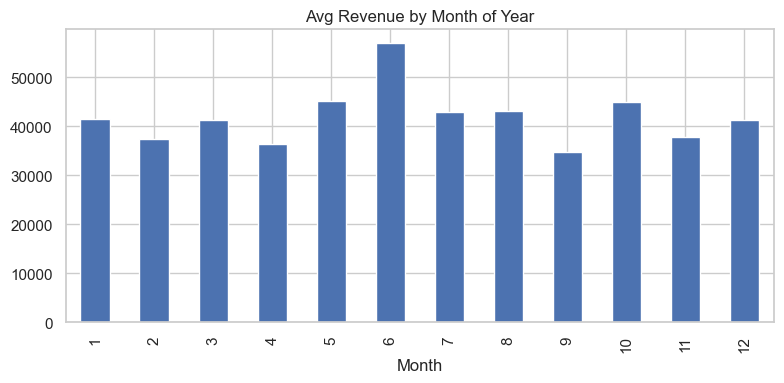

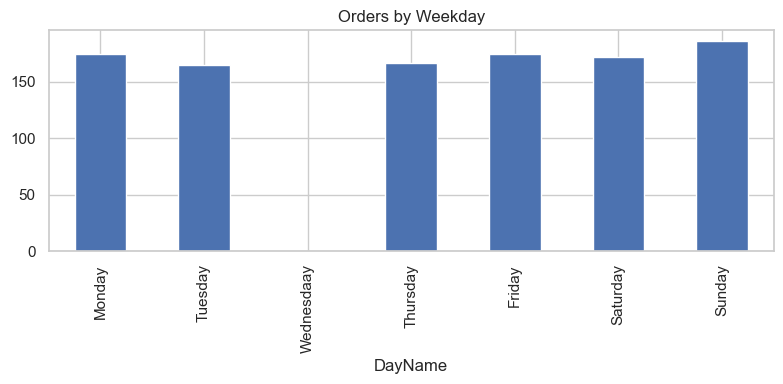

In [70]:
# Seasonality : Average monthly revenue
monthly_avg = df.groupby(["Year", "Month"]).TotalPrice.sum().groupby("Month").mean()
monthly_avg.plot.bar(figsize=(8, 4), title=("Avg Revenue by Month of Year"))
save_show("10: Seasonality")

order = ["Monday", "Tuesday", "Wednesdaay", "Thursday", "Friday", "Saturday", "Sunday"]
df.groupby("DayName").size().reindex(order).plot.bar(figsize= (8,4), title= "Orders by Weekday")
save_show("11: Weekday")